# (DSC555) Data Analysis and Model Development
Author: Tracey Johnson/
Date: 10-14-2026/
Python version 3.13


1. Data Understanding, Exploration, and Feature Engineering
2. Model Selection, Model Training and Evaluation
3. Results Interpretation and Recommendations

README: https://github.com/tdjohnson3210-oss/access-barriers-analysis/blob/main/README.md

In [1]:
import pandas as pd
import requests
import io
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully.")

Libraries imported successfully.


---

---

## Data Understanding, Exploration, and Feature Engineering

### Primary Dataset Overview

The primary dataset used for exploratory data analysis (EDA) combines **American Community Survey (ACS)** estimates with **Rural–Urban Commuting Area (RUCA)** classifications at the census tract level. ACS data provide demographic, economic, housing, internet access, and commuting characteristics for communities across the United States, while RUCA codes classify tracts according to population density, urbanization, and commuting patterns. The datasets were merged using Census tract GEOIDs, creating a unified dataset that captures both socioeconomic conditions and geographic context. This integration allows the examination of how factors such as poverty, vehicle availability, housing characteristics, broadband access, and rurality vary across communities and may be associated with differences in civil court utilization. Following data integration, tract-level measures can be aggregated to the county level for alignment with county-level court filing records and subsequent statistical analysis.

In [2]:
base_url = (
    "https://raw.githubusercontent.com/"
    "tdjohnson3210-oss/access-barriers-analysis/main/data_processed"
)

dfs = []

for i in range(9):
    file_url = f"{base_url}/df_primary_part_{i}.parquet"
    dfs.append(pd.read_parquet(file_url))

df_primary = pd.concat(
    dfs,
    ignore_index=True
)

print(df_primary.shape)

(426949, 72)


In [3]:
print("First 5 rows of the dataset:")
(df_primary.head())

First 5 rows of the dataset:


,geography,households_by_type_total_households_married_couple_family,households_by_type_total_households_cohabiting_couple_household,households_by_type_total_households_male_householder_no_spouse/partner_present,households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone,households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,households_by_type_total_households_female_householder_no_spouse/partner_present,households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone,households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,households_by_type_total_households_households_with_one_or_more_people_under_18_years,...,primaryruca,primaryrucadescription,secondaryruca,secondaryrucadescription,population,landarea,popdensity,transportation_households_no_vehicle,transportation_households_one_vehicle,transportation_households_high_vehicle_access
0,1400000US01001020100,433.0,9.0,99.0,71.0,44.0,152.0,58.0,25.0,217.0,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",1775.0,3.8,467.9,10.0,181.0,259.0
1,1400000US01001020200,202.0,36.0,142.0,92.0,16.0,193.0,99.0,64.0,170.0,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",2055.0,1.3,1602.7,57.0,226.0,91.0
2,1400000US01001020300,657.0,165.0,203.0,152.0,28.0,326.0,154.0,102.0,583.0,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",3216.0,2.1,1557.1,42.0,443.0,475.0
3,1400000US01001020400,967.0,40.0,264.0,141.0,41.0,365.0,271.0,132.0,321.0,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",4246.0,2.5,1722.5,72.0,590.0,313.0
4,1400000US01001020501,1043.0,0.0,211.0,135.0,41.0,452.0,293.0,83.0,555.0,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",4322.0,2.4,1804.4,44.0,485.0,363.0


In [4]:
print("Last 5 rows of the dataset:")
(df_primary.tail())

Last 5 rows of the dataset:


,geography,households_by_type_total_households_married_couple_family,households_by_type_total_households_cohabiting_couple_household,households_by_type_total_households_male_householder_no_spouse/partner_present,households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone,households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,households_by_type_total_households_female_householder_no_spouse/partner_present,households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone,households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,households_by_type_total_households_households_with_one_or_more_people_under_18_years,...,primaryruca,primaryrucadescription,secondaryruca,secondaryrucadescription,population,landarea,popdensity,transportation_households_no_vehicle,transportation_households_one_vehicle,transportation_households_high_vehicle_access
426944,1400000US72153750501,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",3968.0,0.7,5646.2,160.0,779.0,278.0
426945,1400000US72153750502,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",1845.0,0.3,6926.1,110.0,394.0,106.0
426946,1400000US72153750503,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",2155.0,1.3,1692.1,47.0,257.0,158.0
426947,1400000US72153750601,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",4368.0,4.2,1029.9,117.0,550.0,389.0
426948,1400000US72153750602,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",2587.0,6.8,382.4,154.0,392.0,49.0


Check for duplicate and missing values in the dataset.

In [5]:
print("Number of duplicate rows:", df_primary.duplicated().sum())

Number of duplicate rows: 0


In [6]:
print("Count of duplicated rows based on 'geography' and 'year':", df_primary.duplicated(["geography", "year"]).sum())

Count of duplicated rows based on 'geography' and 'year': 0


In [7]:
print("Count of columns with any missing values:", (df_primary.isnull().sum() > 0).sum())
primary_missing = (df_primary.isnull().sum() / len(df_primary) * 100)
(
    primary_missing[primary_missing > 0]
    .sort_values(ascending=False)
)

Count of columns with any missing values: 65


households_by_type_total_households_average_family_size                            2.455563
households_by_type_total_households_average_household_size                         2.429564
households_by_type_total_households_married_couple_family                          1.148849
language_spoken_at_home_population_5_years_and_over_language_other_than_english    1.148849
residence_1_year_ago_population_1_year_and_over                                    1.148849
                                                                                     ...   
countyname20                                                                       0.621151
countycode20                                                                       0.621151
statename20                                                                        0.621151
statefips20                                                                        0.621151
popdensity                                                                      

Check data types.

In [8]:
print("Data types of each column:")
(df_primary.dtypes)

Data types of each column:


geography                                                                                                   object
households_by_type_total_households_married_couple_family                                                  float64
households_by_type_total_households_cohabiting_couple_household                                            float64
households_by_type_total_households_male_householder_no_spouse/partner_present                             float64
households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone    float64
                                                                                                            ...   
landarea                                                                                                   float64
popdensity                                                                                                 float64
transportation_households_no_vehicle                                            

Before further exploratory analysis, categorize barrier columns and create separate dfs for each category.

In [9]:
df_primary.columns.tolist()

['geography',
 'households_by_type_total_households_married_couple_family',
 'households_by_type_total_households_cohabiting_couple_household',
 'households_by_type_total_households_male_householder_no_spouse/partner_present',
 'households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone',
 'households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over',
 'households_by_type_total_households_female_householder_no_spouse/partner_present',
 'households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone',
 'households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over',
 'households_by_type_total_households_households_with_one_or_more_people_under_18_years',
 'households_by_type_total_households_households_with_one_or_more_people_65_years_and_over',
 'households_by_type_total_househ

In [10]:
# Geographic
geo_cols = [
    'geography',
    'year',
    'tract_name',
    'geoid',
    'statefips20',
    'statename20',
    'countyfips20',
    'countycode20',
    'countyname20',
    'urbancore',
    'urbancoretype',
    'primaryruca',
    'primaryrucadescription',
    'secondaryruca',
    'secondaryrucadescription',
    'population',
    'landarea',
    'popdensity'
]


# Household / Family Barriers
household_cols = [
    c for c in df_primary.columns
    if c.startswith('households_by_type_')
]


# Education Barriers
education_cols = [
    c for c in df_primary.columns
    if c.startswith('educational_attainment_')
]


# Disability Barriers
disability_cols = [
    c for c in df_primary.columns
    if c.startswith(
        'disability_status_of_the_civilian_noninstitutionalized_population'
    )
]


# Mobility / Residential Stability Barriers
mobility_cols = [
    c for c in df_primary.columns
    if c.startswith('residence_1_year_ago_')
]


# Language Barriers
language_cols = [
    c for c in df_primary.columns
    if c.startswith('language_spoken_at_home_')
]


# Digital Access Barriers
digital_cols = [
    c for c in df_primary.columns
    if c.startswith('computers_and_internet_use_')
]


# Transportation Barriers
transportation_cols = [
    'transportation_households_no_vehicle',
    'transportation_households_one_vehicle',
    'transportation_households_high_vehicle_access'
]


# Geographic Access / Rurality Barriers
rurality_cols = [
    'urbancore',
    'urbancoretype',
    'primaryruca',
    'primaryrucadescription',
    'secondaryruca',
    'secondaryrucadescription',
    'population',
    'landarea',
    'popdensity'
]


# All barrier categories in one place
barrier_categories = {
    "household": household_cols,
    "education": education_cols,
    "disability": disability_cols,
    "mobility": mobility_cols,
    "language": language_cols,
    "digital": digital_cols,
    "transportation": transportation_cols,
    "rurality": rurality_cols
}

In [11]:
for category, cols in barrier_categories.items():
    print(f"{category}: {len(cols)} columns")

household: 12 columns
education: 10 columns
disability: 7 columns
mobility: 8 columns
language: 12 columns
digital: 2 columns
transportation: 3 columns
rurality: 9 columns


#### Descriptive Statistics

Following data quality checks, exploratory data analysis will be conducted to better understand the distribution and variation of barrier-related variables across census tracts. To improve interpretability and support later modeling, variables were organized into conceptually related barrier domains representing different dimensions of access barriers. The summary statistics presented below provide an initial assessment of the characteristics of each domain and help identify potential patterns, outliers, and relationships within the data.

| Barrier Domain | Description |
|---|---|
| Household | Family composition, household structure, and living arrangements |
| Education | Educational attainment and qualifications |
| Disability | Disability prevalence across age groups |
| Mobility | Residential stability and recent migration patterns |
| Language | Language use and potential English proficiency barriers |
| Digital | Computer ownership and broadband internet access |
| Transportation | Household vehicle availability and transportation access |
| Rurality | Rural-urban characteristics and geographic accessibility |

Univariate analysis.

In [12]:
# Descriptive statistics by barrier domain

for category, cols in barrier_categories.items():

    print("\n" + "="*80)
    print(f"{category.upper()} BARRIERS")
    print("="*80)

    desc = (
        df_primary[cols]
        .describe()
        .T
        .round(2)
    )

    display(desc)


HOUSEHOLD BARRIERS


,count,mean,std,min,25%,50%,75%,max
households_by_type_total_households_married_couple_family,422044.0,707.77,415.27,0.00,414.00,649.00,937.00,10863.0
households_by_type_total_households_cohabiting_couple_household,422044.0,102.43,83.70,0.00,43.00,83.00,141.00,1652.0
households_by_type_total_households_male_householder_no_spouse/partner_present,422044.0,269.98,174.99,0.00,151.00,237.00,351.00,2792.0
households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone,422044.0,190.76,141.20,0.00,95.00,162.00,251.00,2604.0
households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,422044.0,56.95,52.68,0.00,20.00,44.00,79.00,1112.0
households_by_type_total_households_female_householder_no_spouse/partner_present,422044.0,409.64,246.27,0.00,235.00,366.00,538.00,3511.0
households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone,422044.0,231.17,168.08,0.00,114.00,194.00,308.00,2885.0
households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,422044.0,114.17,99.00,0.00,47.00,90.00,153.00,1824.0
households_by_type_total_households_households_with_one_or_more_people_under_18_years,422044.0,449.50,267.26,0.00,266.00,413.00,590.00,8135.0
households_by_type_total_households_households_with_one_or_more_people_65_years_and_over,422044.0,459.76,266.25,0.00,280.00,423.00,594.00,6322.0



EDUCATION BARRIERS


,count,mean,std,min,25%,50%,75%,max
educational_attainment_population_25_years_and_over,422044.0,2686.27,1186.95,0.0,1864.0,2581.0,3388.0,26113.0
educational_attainment_population_25_years_and_over_less_than_9th_grade,422044.0,127.88,173.25,0.0,25.0,68.0,156.0,2806.0
educational_attainment_population_25_years_and_over_9th_to_12th_grade_no_diploma,422044.0,164.51,148.56,0.0,59.0,126.0,228.0,2835.0
educational_attainment_population_25_years_and_over_high_school_graduate_includes_equivalency,422044.0,707.74,412.52,0.0,405.0,656.0,952.0,6402.0
educational_attainment_population_25_years_and_over_some_college_no_degree,422044.0,529.20,295.11,0.0,318.0,485.0,692.0,4815.0
educational_attainment_population_25_years_and_over_associate's_degree,422044.0,234.71,156.59,0.0,122.0,207.0,316.0,2572.0
educational_attainment_population_25_years_and_over_bachelor's_degree,422044.0,562.10,434.31,0.0,242.0,454.0,780.0,10269.0
educational_attainment_population_25_years_and_over_graduate_or_professional_degree,422044.0,360.12,367.28,0.0,110.0,241.0,491.0,7059.0
educational_attainment_population_25_years_and_over_high_school_graduate_or_higher,422044.0,2393.88,1127.98,0.0,1601.0,2273.0,3051.0,25455.0
educational_attainment_population_25_years_and_over_bachelor's_degree_or_higher,422044.0,922.22,760.61,0.0,368.0,708.0,1279.0,17328.0



DISABILITY BARRIERS


,count,mean,std,min,25%,50%,75%,max
disability_status_of_the_civilian_noninstitutionalized_population_total_civilian_noninstitutionalized_population_with_a_disability,422044.0,498.38,273.75,0.0,304.0,458.0,649.0,3485.0
disability_status_of_the_civilian_noninstitutionalized_population_under_18_years,422044.0,870.44,541.46,0.0,501.0,789.0,1143.0,15466.0
disability_status_of_the_civilian_noninstitutionalized_population_under_18_years_with_a_disability,422044.0,39.75,49.93,0.0,5.0,25.0,56.0,920.0
disability_status_of_the_civilian_noninstitutionalized_population_18_to_64_years,422044.0,2358.63,1120.03,0.0,1585.0,2240.0,2998.0,26207.0
disability_status_of_the_civilian_noninstitutionalized_population_18_to_64_years_with_a_disability,422044.0,248.11,164.17,0.0,129.0,217.0,333.0,2545.0
disability_status_of_the_civilian_noninstitutionalized_population_65_years_and_over,422044.0,632.47,383.87,0.0,374.0,577.0,820.0,10546.0
disability_status_of_the_civilian_noninstitutionalized_population_65_years_and_over_with_a_disability,422044.0,210.52,141.71,0.0,112.0,185.0,280.0,2971.0


... (6 outputs left out)


TRANSPORTATION BARRIERS


,count,mean,std,min,25%,50%,75%,max
transportation_households_no_vehicle,426949.0,125.14,216.96,0.0,25.0,67.0,146.0,6086.0
transportation_households_one_vehicle,426949.0,487.78,300.70,0.0,275.0,431.0,641.0,4857.0
transportation_households_high_vehicle_access,426949.0,326.20,229.78,0.0,153.0,291.0,458.0,3495.0



RURALITY BARRIERS


,count,mean,std,min,25%,50%,75%,max
urbancore,424297.0,0.780491,0.413914,0.0,1.0,1.0,1.0,1.0
primaryruca,424297.0,2.727757,6.803715,1.0,1.0,1.0,2.0,99.0
secondaryruca,424297.0,2.727757,6.803715,1.0,1.0,1.0,2.0,99.0
population,424297.0,3918.718912,1716.226498,0.0,2725.0,3756.0,4925.0,37892.0
landarea,424297.0,41.640349,501.361644,0.0,0.7,1.7,10.9,85554.7
popdensity,424297.0,5410.815435,12285.131509,0.0,313.5,2206.8,5379.6,287370.2


Observations:

- All eight barrier domains exhibit substantial variation across census tracts, supporting their usefulness for further analysis.
- Several variables show large gaps between median and maximum values, suggesting the presence of high-barrier tracts and right-skewed distributions.
- Education, disability, and mobility measures demonstrate particularly wide ranges, indicating considerable differences across communities.
- Language barrier variables appear highly concentrated in specific tracts, with many observations near zero and a smaller number of tracts exhibiting substantially larger values.
- Transportation barriers vary meaningfully across tracts, supporting their inclusion as a distinct access-related domain.
- Digital access measures show less variation than several other domains but still indicate disparities in technology and broadband access.
- Rurality variables reveal significant geographic diversity, ranging from dense urban areas to highly rural and sparsely populated regions.


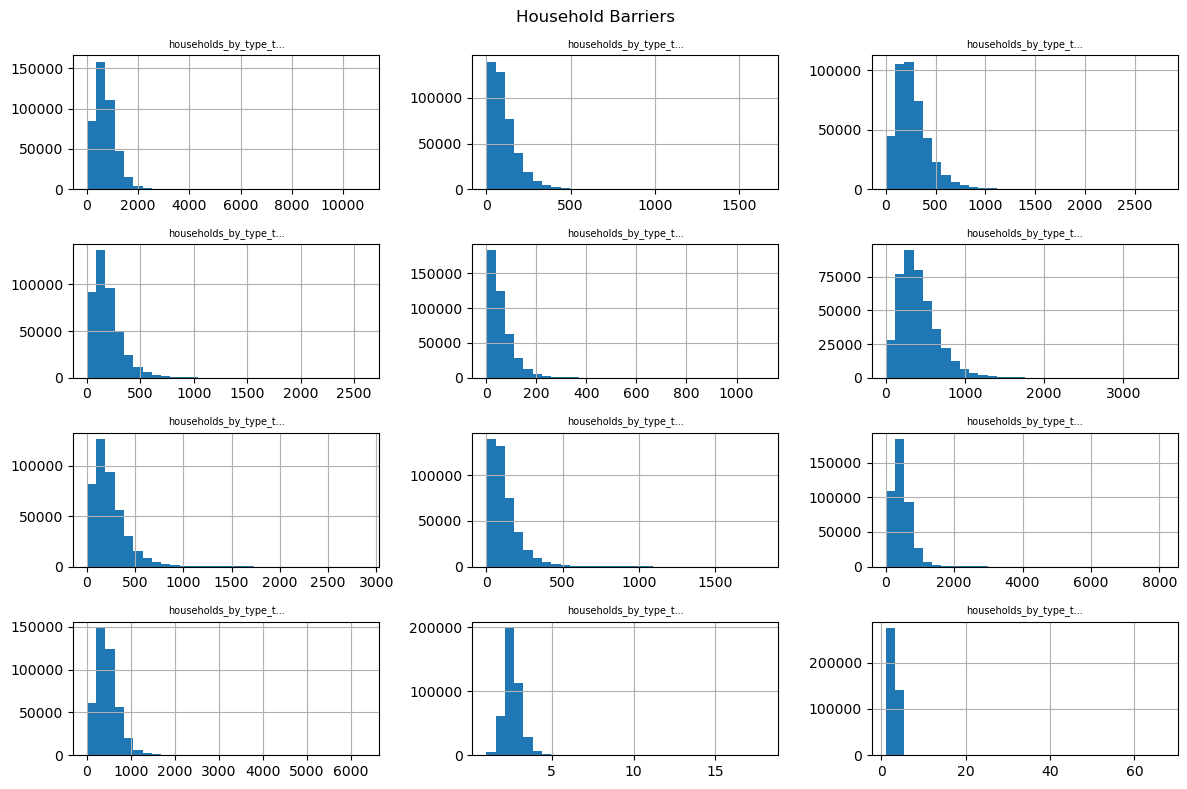

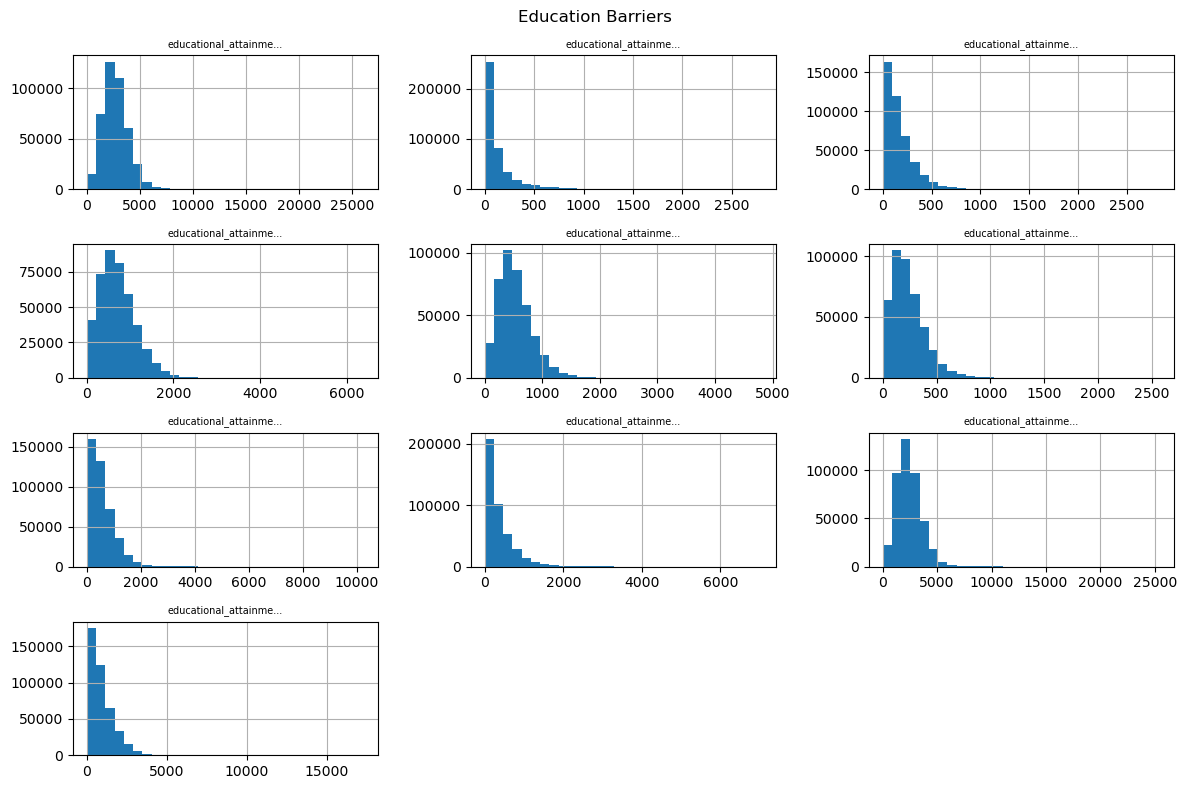

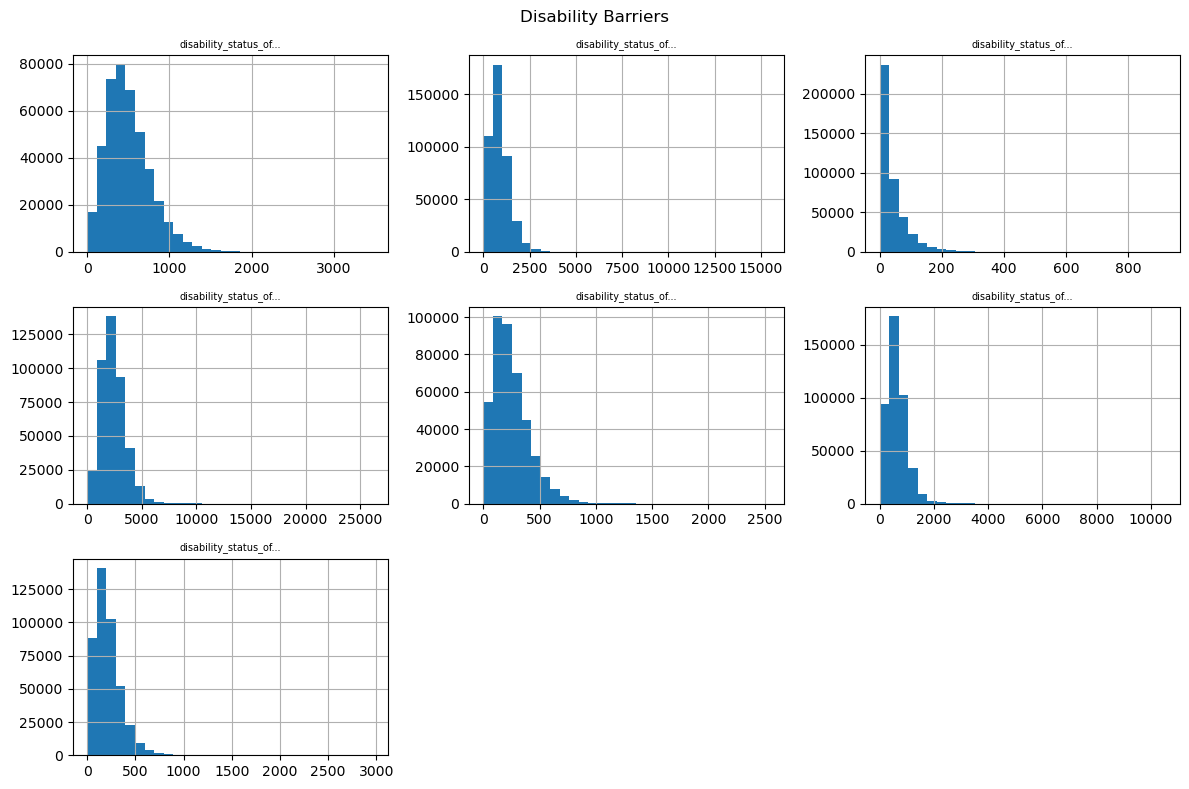

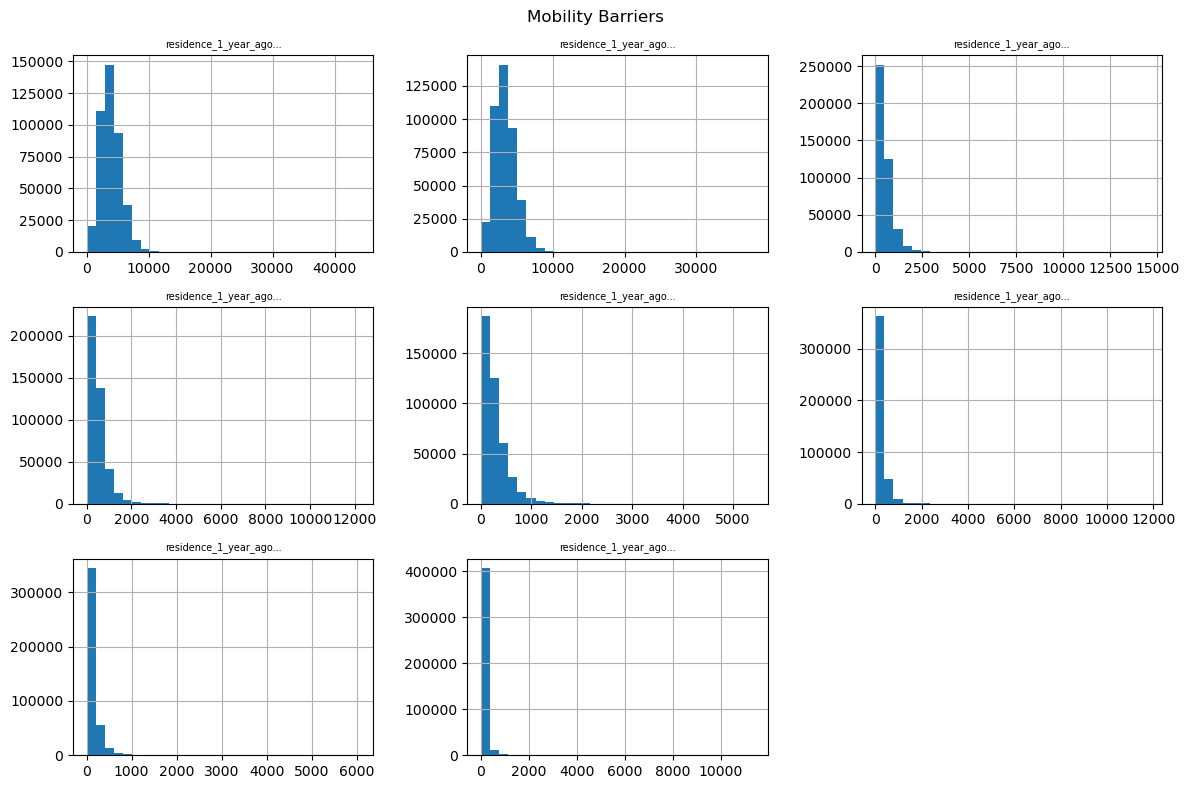

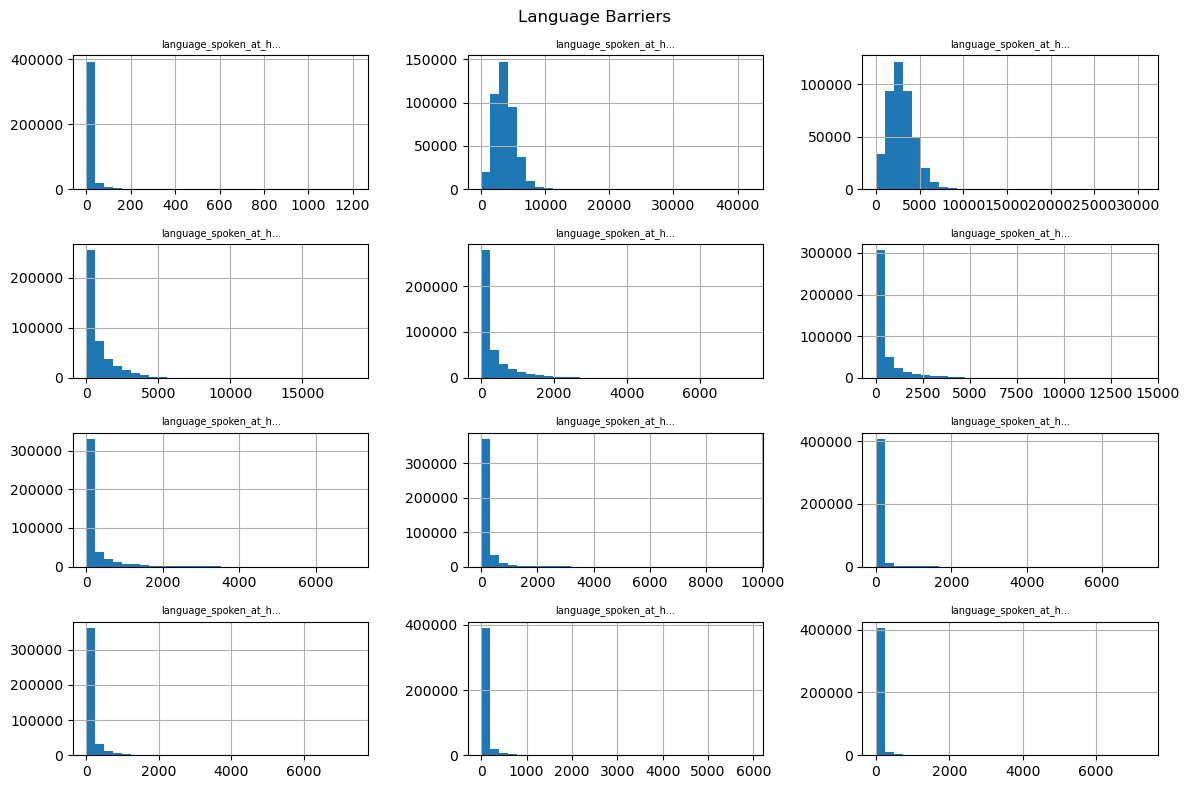

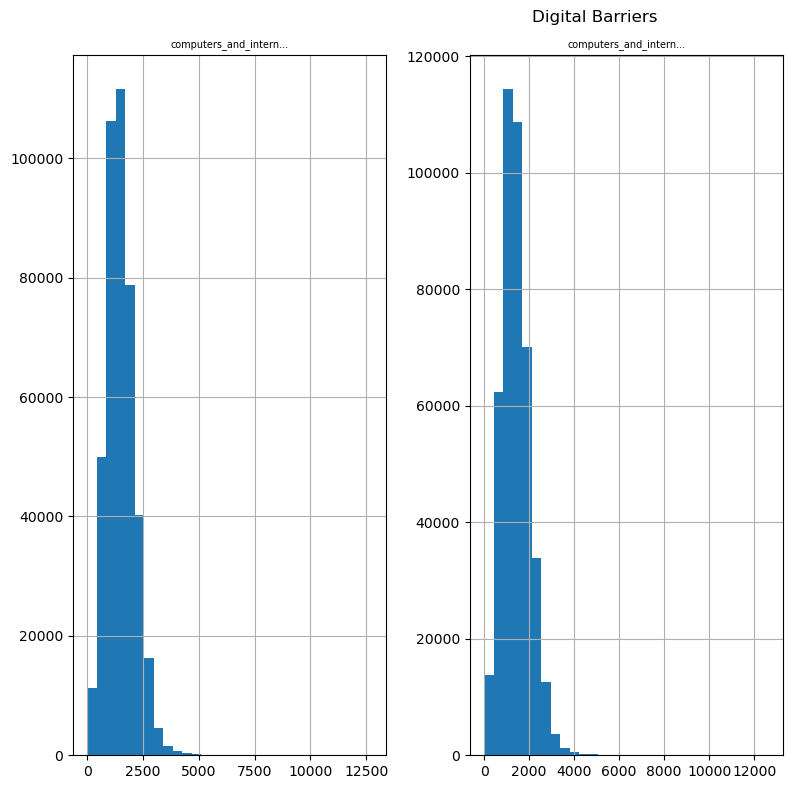

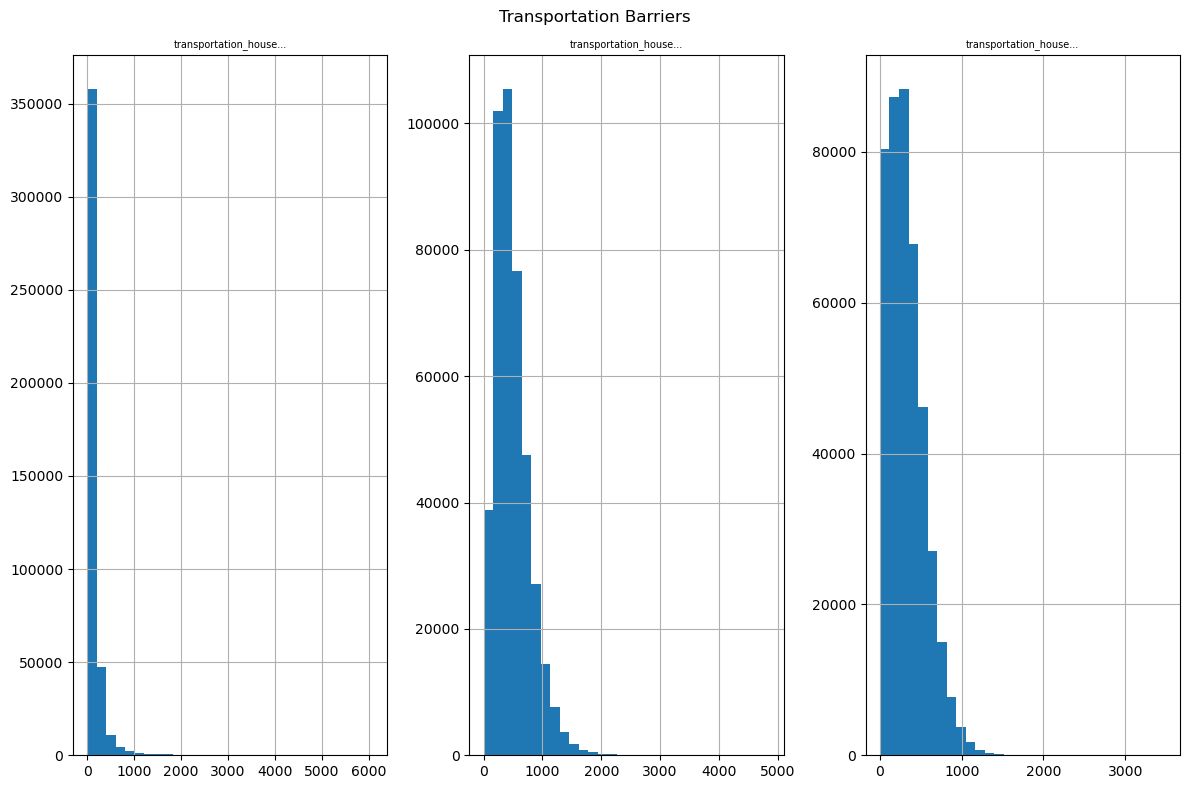

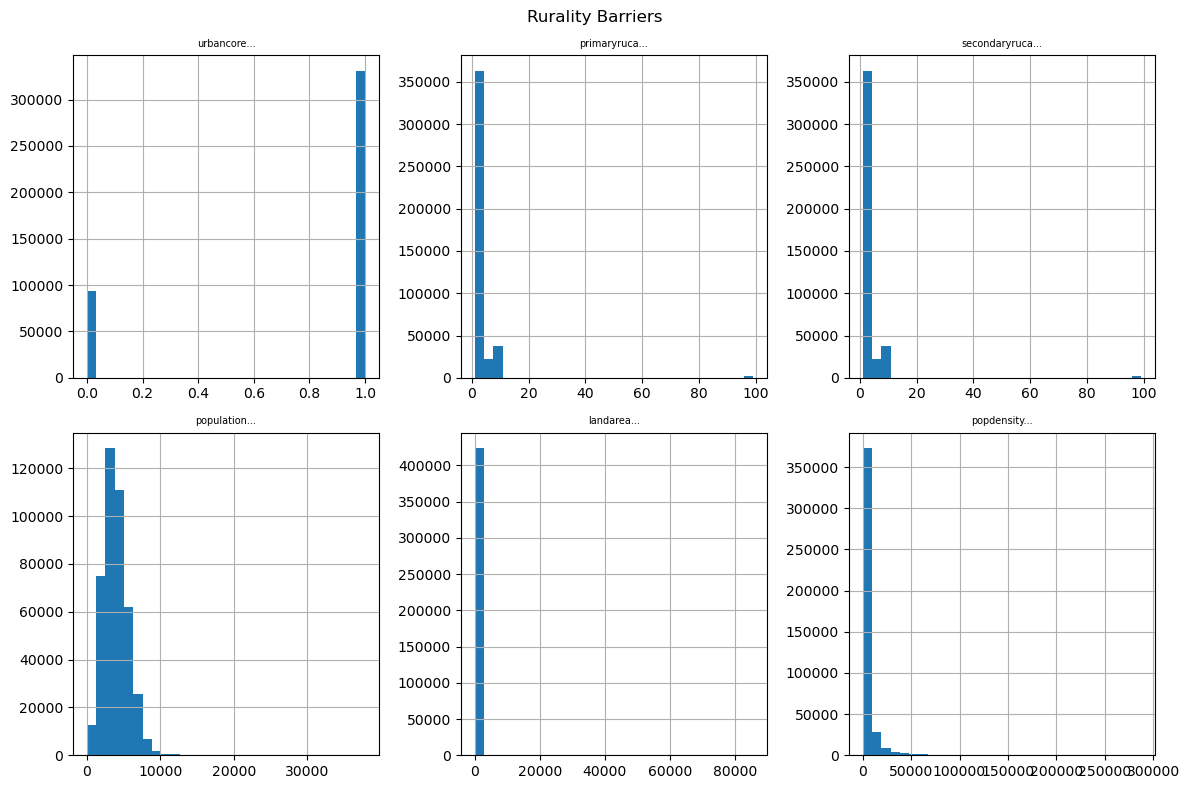

In [13]:
for category, cols in barrier_categories.items():

    df_primary[cols].hist(
        bins=30,
        figsize=(12, 8),
        layout=(-1, 3)
    )

    plt.suptitle(f"{category.title()} Barriers")

    for ax in plt.gcf().axes:
        ax.set_title(
            ax.get_title()[:20] + "...",
            fontsize=7
        )

    plt.tight_layout()
    plt.show()

Observations:

Household Barriers
- Most household measures are right-skewed.
- Household barriers vary substantially across tracts.

Education Barriers
- Educational attainment varies considerably across communities.
- Most education variables exhibit positive skewness.

Disability Barriers
- Disability measures are concentrated in a smaller number of tracts.
- Several variables contain long upper tails.

Mobility Barriers
- Residential mobility is unevenly distributed across tracts.
- Most mobility variables are strongly right-skewed.

Language Barriers
- Language barriers are highly concentrated in specific communities.
- Most language variables contain many low-value observations and a few large outliers.

Digital Barriers
- Digital access is more evenly distributed than other domains.
- Some disparities in broadband and computer access remain evident.

Transportation Barriers
- Transportation access varies substantially across communities.
- Households with limited vehicle access are more common than households with no vehicle access.

Rurality Barriers
- Rurality measures indicate considerable geographic diversity.
- Population density and land area exhibit strong right-skewed distributions.

Outlier detection.

In [14]:
n = len(df_primary)

for col in transportation_cols:
    q1 = df_primary[col].quantile(.25)
    q3 = df_primary[col].quantile(.75)
    iqr = q3 - q1

    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr

    outliers = (
        (df_primary[col] < lower) |
        (df_primary[col] > upper)
    ).sum()

    print(
        f"{col}: {outliers:,} outliers ({outliers/n:.1%})"
    )

transportation_households_no_vehicle: 31,478 outliers (7.4%)
transportation_households_one_vehicle: 11,718 outliers (2.7%)
transportation_households_high_vehicle_access: 7,836 outliers (1.8%)


Observations:

- Boxplots indicate substantial variation across transportation measures and reveal positively skewed distributions with numerous upper-tail observations.
- Households with one vehicle were generally more common than households with no vehicle, while high vehicle-access households also exhibited considerable variability.
- The observed distributions suggest that transportation-related barriers are unevenly distributed across census tracts and support the inclusion of transportation as a distinct barrier domain.

Bivariate analysis.

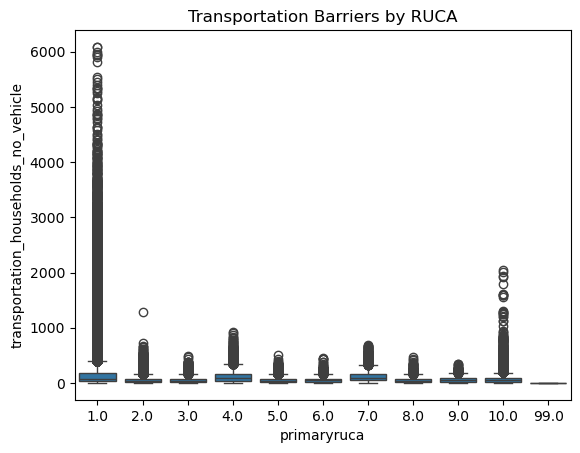

In [15]:
sns.boxplot(
    data=df_primary,
    x="primaryruca",
    y="transportation_households_no_vehicle"
)

plt.title("Transportation Barriers by RUCA")
plt.show()

In [16]:
for col in transportation_cols:

    print(f"\nTop 10: {col}")

    display(
        df_primary[
            ["statename20", "countyname20", "tract_name", col]
        ]
        .nlargest(10, col)
    )


Top 10: transportation_households_no_vehicle


,statename20,countyname20,tract_name,transportation_households_no_vehicle
393919,New York,New York County,Census Tract 44; New York County; New York,6086.0
52460,New York,New York County,Census Tract 139,6076.0
223142,New York,New York County,Census Tract 44; New York County; New York,5997.0
308538,New York,New York County,Census Tract 44; New York County; New York,5962.0
137746,New York,New York County,Census Tract 44,5943.0
137855,New York,New York County,Census Tract 139,5931.0
52351,New York,New York County,Census Tract 44,5901.0
223251,New York,New York County,Census Tract 139; New York County; New York,5811.0
308647,New York,New York County,Census Tract 139; New York County; New York,5537.0
308558,New York,New York County,Census Tract 66; New York County; New York,5507.0



Top 10: transportation_households_one_vehicle


,statename20,countyname20,tract_name,transportation_households_one_vehicle
362660,Florida,Sumter County,Census Tract 9114.02; Sumter County; Florida,4857.0
366861,Illinois,Cook County,Census Tract 818; Cook County; Illinois,4824.0
191883,Florida,Sumter County,Census Tract 9114.02; Sumter County; Florida,4456.0
277279,Florida,Sumter County,Census Tract 9114.02; Sumter County; Florida,4445.0
362653,Florida,Sumter County,Census Tract 9112.04; Sumter County; Florida,4441.0
281480,Illinois,Cook County,Census Tract 818; Cook County; Illinois,4295.0
277272,Florida,Sumter County,Census Tract 9112.04; Sumter County; Florida,4261.0
418362,Texas,Travis County,Census Tract 454; Travis County; Texas,4232.0
264869,California,Orange County,Census Tract 626.10; Orange County; California,4115.0
350250,California,Orange County,Census Tract 626.10; Orange County; California,4112.0



Top 10: transportation_households_high_vehicle_access


,statename20,countyname20,tract_name,transportation_households_high_vehicle_access
415775,Texas,Harris County,Census Tract 5429.02; Harris County; Texas,3495.0
414474,Texas,Fort Bend County,Census Tract 6732.02; Fort Bend County; Texas,3197.0
412356,Texas,Bexar County,Census Tract 1720.02; Bexar County; Texas,2955.0
326974,Texas,Bexar County,Census Tract 1720.02; Bexar County; Texas,2852.0
412936,Texas,Collin County,Census Tract 303.07; Collin County; Texas,2658.0
327554,Texas,Collin County,Census Tract 303.07; Collin County; Texas,2463.0
330393,Texas,Harris County,Census Tract 5429.02; Harris County; Texas,2333.0
329092,Texas,Fort Bend County,Census Tract 6732.02; Fort Bend County; Texas,2276.0
156197,Texas,Bexar County,Census Tract 1720.02,2244.0
265402,California,Riverside County,Census Tract 406.09; Riverside County; California,2232.0


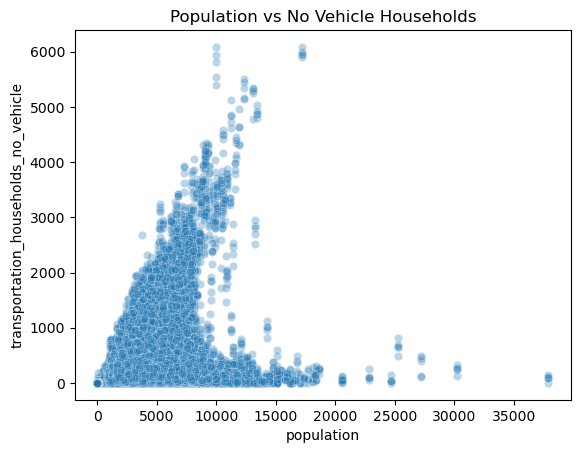

In [17]:
sns.scatterplot(
    data=df_primary,
    x="population",
    y="transportation_households_no_vehicle",
    alpha=.3
)

plt.title("Population vs No Vehicle Households")
plt.show()

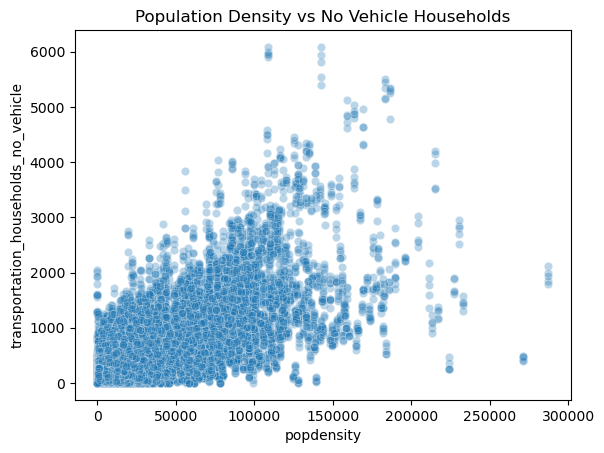

In [18]:
sns.scatterplot(
    data=df_primary,
    x="popdensity",
    y="transportation_households_no_vehicle",
    alpha=.3
)

plt.title("Population Density vs No Vehicle Households")
plt.show()

Multivariate Analysis: Correlation between all access barriers.

C:\Users\tdjoh\AppData\Local\Temp\ipykernel_26672\1771934888.py:41: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


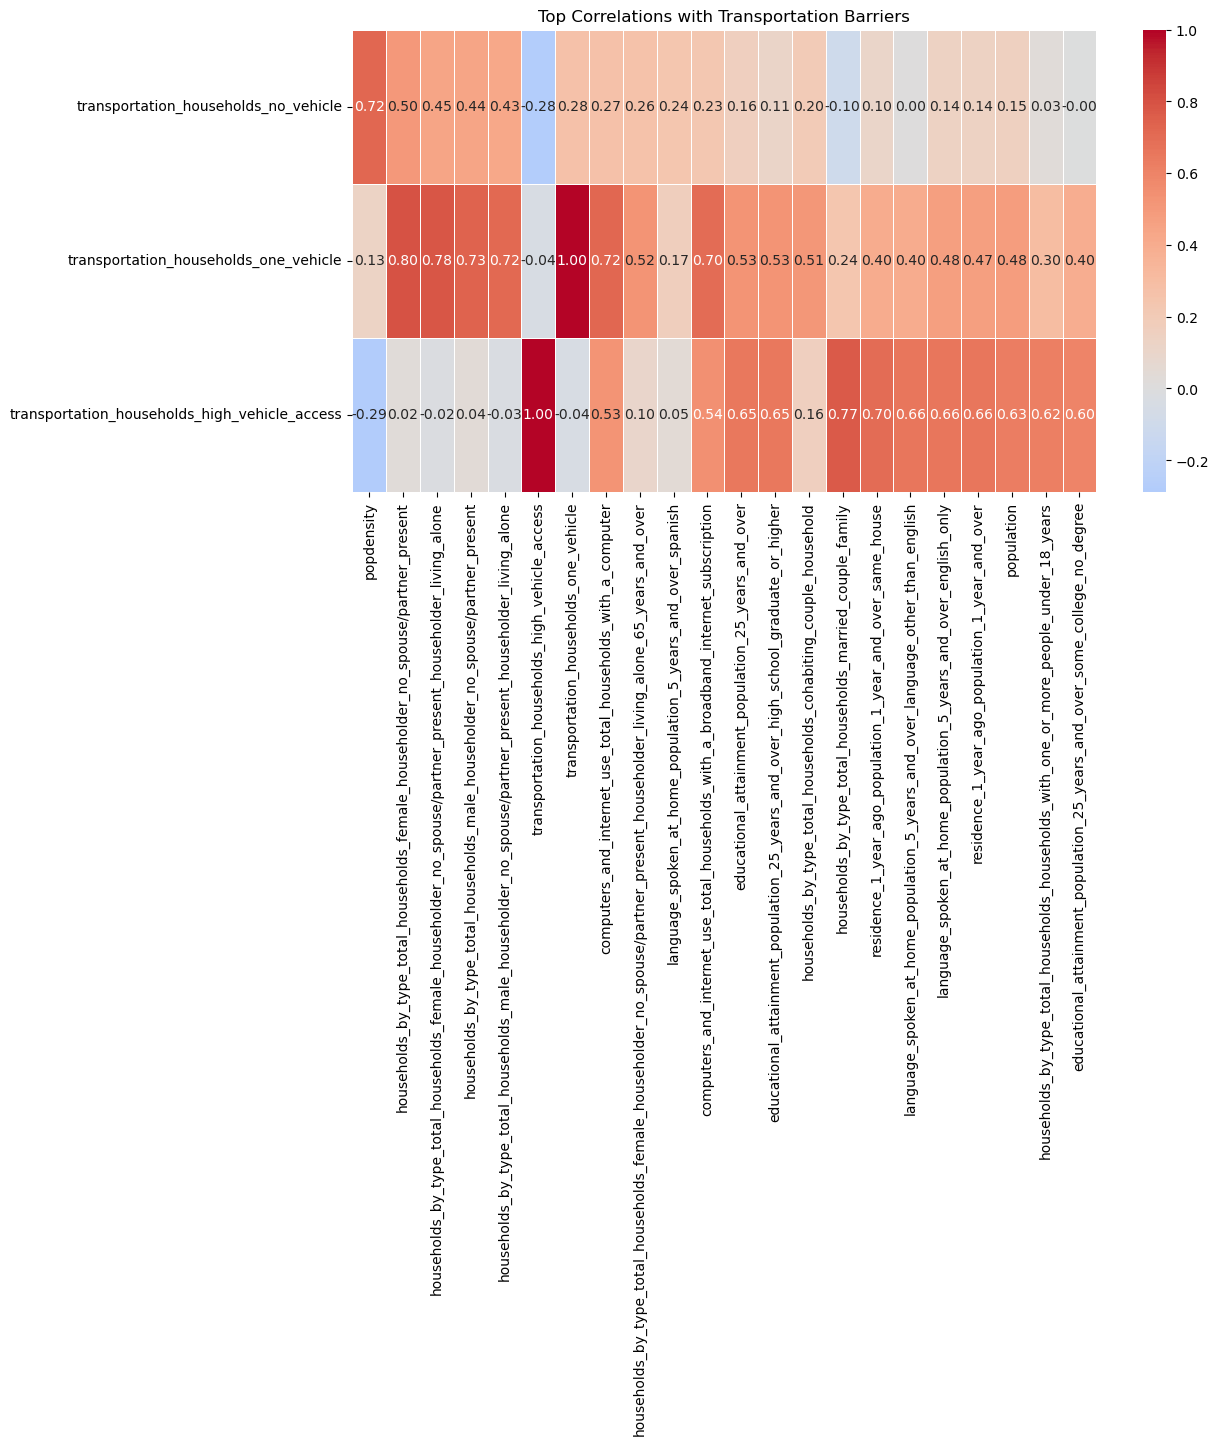

In [19]:
# Correlation matrix
corr = df_primary.select_dtypes(include="number").corr()

# Collect strongest correlations for transportation variables
rows = []

for transport_var in transportation_cols:

    top_corrs = (
        corr[transport_var]
        .drop(transport_var)
        .abs()
        .sort_values(ascending=False)
        .head(10)
        .index
    )

    for var in top_corrs:
        rows.append(var)

# Unique variables
top_vars = list(dict.fromkeys(rows))

# Build heatmap dataset
heatmap_df = corr.loc[transportation_cols, top_vars]

plt.figure(figsize=(12, 6))

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=.5
)

plt.title("Top Correlations with Transportation Barriers")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [20]:
numeric_corr = df_primary.select_dtypes(include="number").corr()

for transport_var in transportation_cols:

    print(f"\n{'='*100}")
    print(transport_var.upper())
    print('='*100)

    display(
        numeric_corr[transport_var]
        .drop(transport_var)
        .sort_values(key=abs, ascending=False)
        .head(15)
        .to_frame("correlation")
        .round(2)
    )


TRANSPORTATION_HOUSEHOLDS_NO_VEHICLE


,correlation
popdensity,0.72
households_by_type_total_households_female_householder_no_spouse/partner_present,0.50
households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone,0.45
households_by_type_total_households_male_householder_no_spouse/partner_present,0.44
households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone,0.43
transportation_households_high_vehicle_access,-0.28
transportation_households_one_vehicle,0.28
computers_and_internet_use_total_households_with_a_computer,0.27
households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,0.26
language_spoken_at_home_population_5_years_and_over_spanish,0.24



TRANSPORTATION_HOUSEHOLDS_ONE_VEHICLE


,correlation
households_by_type_total_households_female_householder_no_spouse/partner_present,0.80
households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone,0.78
households_by_type_total_households_male_householder_no_spouse/partner_present,0.73
computers_and_internet_use_total_households_with_a_computer,0.72
households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone,0.72
computers_and_internet_use_total_households_with_a_broadband_internet_subscription,0.70
educational_attainment_population_25_years_and_over,0.53
educational_attainment_population_25_years_and_over_high_school_graduate_or_higher,0.53
households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,0.52
households_by_type_total_households_cohabiting_couple_household,0.51



TRANSPORTATION_HOUSEHOLDS_HIGH_VEHICLE_ACCESS


,correlation
households_by_type_total_households_married_couple_family,0.77
residence_1_year_ago_population_1_year_and_over_same_house,0.70
language_spoken_at_home_population_5_years_and_over_language_other_than_english,0.66
language_spoken_at_home_population_5_years_and_over_english_only,0.66
residence_1_year_ago_population_1_year_and_over,0.66
educational_attainment_population_25_years_and_over_high_school_graduate_or_higher,0.65
educational_attainment_population_25_years_and_over,0.65
population,0.63
households_by_type_total_households_households_with_one_or_more_people_under_18_years,0.62
educational_attainment_population_25_years_and_over_some_college_no_degree,0.60


#### Geographic Column Analysis

In [21]:
geo_cols

['geography',
 'year',
 'tract_name',
 'geoid',
 'statefips20',
 'statename20',
 'countyfips20',
 'countycode20',
 'countyname20',
 'urbancore',
 'urbancoretype',
 'primaryruca',
 'primaryrucadescription',
 'secondaryruca',
 'secondaryrucadescription',
 'population',
 'landarea',
 'popdensity']

Check missing percentages.

In [22]:
(
    df_primary[geo_cols]
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
    .rename("Missing %")
    .to_frame()
)

,Missing %
urbancore,0.62
urbancoretype,0.62
landarea,0.62
population,0.62
secondaryrucadescription,0.62
secondaryruca,0.62
primaryrucadescription,0.62
primaryruca,0.62
popdensity,0.62
countyname20,0.62


Check quality of `geoid` column.

In [23]:
print("Rows:", len(df_primary))
print("Unique GEOIDs:", df_primary['geoid'].nunique())
print("Duplicate GEOIDs:", df_primary['geoid'].duplicated().sum())
print("Length of GEOIDs:", df_primary['geoid'].str.len().unique())

Rows: 426949
Unique GEOIDs: 86279
Duplicate GEOIDs: 340670
Length of GEOIDs: [11]


State distributions.

In [24]:
df_primary['statename20'].value_counts()

statename20
California              45645
Texas                   34480
New York                27026
Florida                 25800
Pennsylvania            17230
Illinois                16325
Ohio                    15840
Michigan                15085
Georgia                 13980
North Carolina          13360
Virginia                10990
New Jersey              10905
Washington               8920
Arizona                  8825
Tennessee                8505
Indiana                  8480
Missouri                 8270
Massachusetts            8100
Wisconsin                7710
Minnesota                7525
Maryland                 7375
Colorado                 7235
Alabama                  7185
Louisiana                6940
South Carolina           6615
Kentucky                 6530
Oklahoma                 6025
Oregon                   5005
Puerto Rico              4905
Iowa                     4480
Mississippi              4390
Kansas                   4145
Arkansas                 411

<Axes: title={'center': 'Top 20 States by Number of Tracts'}, xlabel='statename20'>

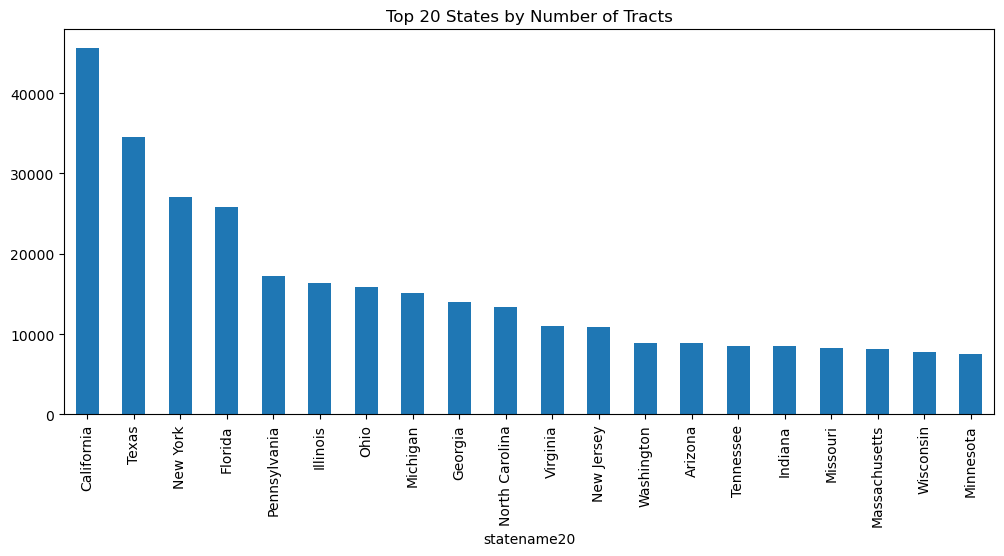

In [25]:
(
    df_primary['statename20']
    .value_counts()
    .head(20)
    .plot(
        kind='bar',
        figsize=(12,5),
        title='Top 20 States by Number of Tracts'
    )
)

Population distributions.

In [26]:
df_primary['population'].describe()

count    424297.000000
mean       3918.718912
std        1716.226498
min           0.000000
25%        2725.000000
50%        3756.000000
75%        4925.000000
max       37892.000000
Name: population, dtype: float64

<Axes: >

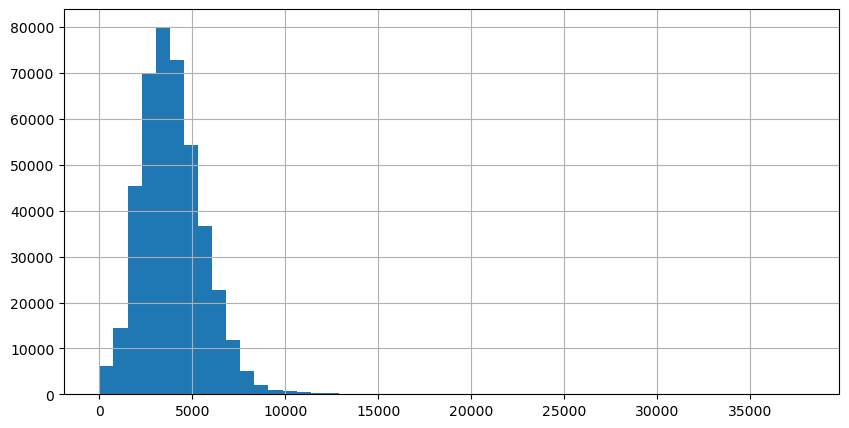

In [27]:
df_primary['population'].hist(
    bins=50,
    figsize=(10,5)
)

In [28]:
print("Population Quality Check (IQR Method)\n")

Q1 = df_primary['population'].quantile(0.25)
Q3 = df_primary['population'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

population_outliers = df_primary.loc[
    df_primary['population'] > upper_bound,
    [
        'year',
        'geoid',
        'statename20',
        'countyname20',
        'tract_name',
        'population'
    ]
]

print(f"Typical tract population range: {Q1:,.0f} - {Q3:,.0f}")
print(f"IQR upper threshold: {upper_bound:,.0f}")
print(f"Number of high-population tract-years: {len(population_outliers):,}")
print(f"Unique tracts affected: {population_outliers['geoid'].nunique():,}")

population_outliers.sort_values(
    'population',
    ascending=False
).head(25)

Population Quality Check (IQR Method)

Typical tract population range: 2,725 - 4,925
IQR upper threshold: 8,225
Number of high-population tract-years: 5,487
Unique tracts affected: 1,098


,year,geoid,statename20,countyname20,tract_name,population
352679,2024,06073018700,California,San Diego County,Census Tract 187; San Diego County; California,37892.0
96507,2021,06073018700,California,San Diego County,Census Tract 187,37892.0
11112,2020,06073018700,California,San Diego County,Census Tract 187,37892.0
181902,2022,06073018700,California,San Diego County,Census Tract 187; San Diego County; California,37892.0
267298,2023,06073018700,California,San Diego County,Census Tract 187; San Diego County; California,37892.0
156197,2021,48029172002,Texas,Bexar County,Census Tract 1720.02,30199.0
241593,2022,48029172002,Texas,Bexar County,Census Tract 1720.02; Bexar County; Texas,30199.0
412356,2024,48029172002,Texas,Bexar County,Census Tract 1720.02; Bexar County; Texas,30199.0
326974,2023,48029172002,Texas,Bexar County,Census Tract 1720.02; Bexar County; Texas,30199.0
70802,2020,48029172002,Texas,Bexar County,Census Tract 1720.02,30199.0


In [29]:
print("Population Density Quality Check (IQR Method)\n")

Q1 = df_primary['popdensity'].quantile(0.25)
Q3 = df_primary['popdensity'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

density_outliers = df_primary.loc[
    df_primary['popdensity'] > upper_bound,
    [
        'year',
        'geoid',
        'statename20',
        'countyname20',
        'tract_name',
        'population',
        'landarea',
        'popdensity'
    ]
]

print(f"Typical tract density range: {Q1:,.2f} - {Q3:,.2f}")
print(f"IQR upper threshold: {upper_bound:,.2f}")
print(f"Number of high-density tract-years: {len(density_outliers):,}")
print(f"Unique tracts affected: {density_outliers['geoid'].nunique():,}")

density_outliers.sort_values(
    'popdensity',
    ascending=False
).head(25)

Population Density Quality Check (IQR Method)

Typical tract density range: 313.50 - 5,379.60
IQR upper threshold: 12,978.75
Number of high-density tract-years: 35,493
Unique tracts affected: 7,134


,year,geoid,statename20,countyname20,tract_name,population,landarea,popdensity
137877,2021,36061015403,New York,New York County,Census Tract 154.03,5738.0,0.0,287370.2
52482,2020,36061015403,New York,New York County,Census Tract 154.03,5738.0,0.0,287370.2
223273,2022,36061015403,New York,New York County,Census Tract 154.03; New York County; New York,5738.0,0.0,287370.2
394050,2024,36061015403,New York,New York County,Census Tract 154.03; New York County; New York,5738.0,0.0,287370.2
308669,2023,36061015403,New York,New York County,Census Tract 154.03; New York County; New York,5738.0,0.0,287370.2
25189,2020,17031030702,Illinois,Cook County,Census Tract 307.02,2318.0,0.0,270944.7
366757,2024,17031030702,Illinois,Cook County,Census Tract 307.02; Cook County; Illinois,2318.0,0.0,270944.7
195980,2022,17031030702,Illinois,Cook County,Census Tract 307.02; Cook County; Illinois,2318.0,0.0,270944.7
110584,2021,17031030702,Illinois,Cook County,Census Tract 307.02,2318.0,0.0,270944.7
281376,2023,17031030702,Illinois,Cook County,Census Tract 307.02; Cook County; Illinois,2318.0,0.0,270944.7


Urban/Rural Distribution

In [30]:
df_primary['primaryrucadescription'].value_counts()

primaryrucadescription
Metropolitan core              291491
Metropolitan high commuting     42543
Rural area                      32299
Micropolitan core               23533
Micropolitan high commuting     11214
Small town core                  7520
Metropolitan low commuting       5712
Micropolitan low commuting       3447
Small town high commuting        3060
Not coded                        1793
Small town low commuting         1685
Name: count, dtype: int64

<Axes: xlabel='primaryrucadescription'>

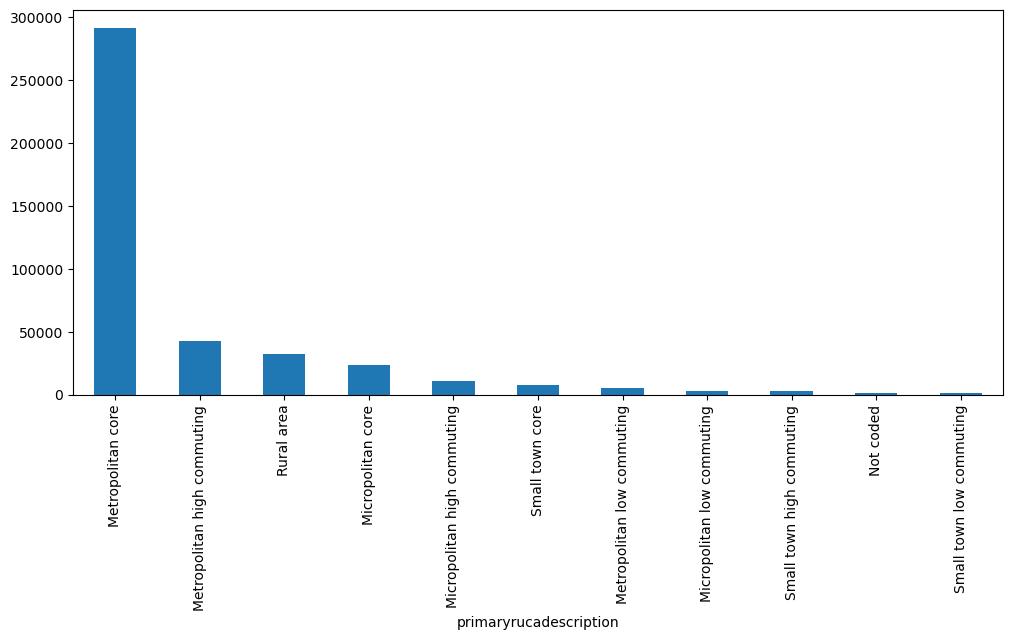

In [31]:
(
    df_primary['primaryrucadescription']
    .value_counts()
    .plot(
        kind='bar',
        figsize=(12,5)
    )
)

---

### Secondary Dataset Overview

National Center for State Courts (NCSC) Court Statistics Project (CSP). The CSP dataset serves as a secondary dataset in this study by providing annual state-level measures of civil court activity. The data consist of structured, aggregated administrative court records that summarize civil caseload characteristics, including filing volumes, case types, and case dispositions. As a state-year panel dataset, each observation represents a single state in a given year rather than an individual case or litigant. The dataset contains quantitative count data and categorical case classifications, allowing for the examination of longitudinal trends in civil court utilization and comparisons across jurisdictions. Because the data are aggregated and de-identified, no personally identifiable information is included. The CSP data are used to provide national context for civil filing patterns and broader changes in court activity that may inform interpretation of local-level access-to-justice trends.

In [32]:
url = "https://raw.githubusercontent.com/tdjohnson3210-oss/access-barriers-analysis/main"
df_secondary = pd.read_parquet(
    f"{url}/data_processed/df_csp_processed.parquet"
)

View historical data.

In [33]:
print("First 5 rows of secondary data")
print(df_secondary.head())
print("Last 5 rows of secondary data")
print(df_secondary.tail())

First 5 rows of secondary data
                                     id reportingunitidentification  \
0  095CD8EC-E08F-41DC-B0C7-01D1989CBE9F                          GJ   
1  F3721030-90AC-44EA-95DB-0302B759F981                          GJ   
2  2DE154B9-E4C8-49B0-91B7-05AC3DDF5723                          GJ   
3  BD4ADFD6-791D-4D25-8692-06C971D044BC                          LJ   
4  C3CB11C7-9533-4817-ADC9-08B76143DE94                          GJ   

   reportingdate reportingstate reportingjurisdiction       casecategory  \
0           2023             IN                    GJ  CivilCaseCategory   
1           2020             MN                    GJ  CivilCaseCategory   
2           2015             MO                    GJ  CivilCaseCategory   
3           2021             GA                    LJ  CivilCaseCategory   
4           2017             IN                    GJ  CivilCaseCategory   

   newfiling  reopened  reactivated  totalincoming  ...  totaloutgoing  \
0   328484.

In [34]:
df_secondary.columns

Index(['id', 'reportingunitidentification', 'reportingdate', 'reportingstate',
       'reportingjurisdiction', 'casecategory', 'newfiling', 'reopened',
       'reactivated', 'totalincoming', 'entryofjudgement',
       'reopeneddisposition', 'placedoninactivestatus', 'totaloutgoing',
       'endpendingactive', 'endpendinginactive', 'totalendpending',
       'casewithselfrepresentedlitigants', 'casewithinterpreters', 'jurytrial',
       'benchnonjurytrial', 'nontrialdisposition', 'totaldispositions'],
      dtype='object')

Identify any duplicate or missing values in the dataset.

In [35]:
print("Number of duplicate rows:", df_secondary.duplicated().sum())

Number of duplicate rows: 0


In [36]:
# any missing values in the secondary dataframe
print("Count of columns with any missing values:", (df_secondary.isnull().sum() > 0).sum())

Count of columns with any missing values: 0


Check data types.

In [37]:
print(df_secondary.dtypes)

id                                   object
reportingunitidentification          object
reportingdate                         Int64
reportingstate                       object
reportingjurisdiction                object
casecategory                         object
newfiling                           float64
reopened                            float64
reactivated                         float64
totalincoming                       float64
entryofjudgement                    float64
reopeneddisposition                 float64
placedoninactivestatus              float64
totaloutgoing                       float64
endpendingactive                    float64
endpendinginactive                  float64
totalendpending                     float64
casewithselfrepresentedlitigants    float64
casewithinterpreters                float64
jurytrial                           float64
benchnonjurytrial                   float64
nontrialdisposition                 float64
totaldispositions               

#### Descriptive Statistics

Descriptive statistics are examined to summarize the court civil dataset and assess data quality prior to analysis. The dataset includes reporting year, state and jurisdiction information, case categories, filing and disposition activity, pending caseload measures, and indicators related to self-represented litigants, interpreters, and trial types.

Univariate analysis.

In [38]:
print("Descriptive Statistics for Numerical Columns")
print(df_secondary.describe())

Descriptive Statistics for Numerical Columns
       reportingdate     newfiling     reopened  reactivated  totalincoming  \
count           56.0      56.00000    56.000000    56.000000      56.000000   
mean     2020.732143  185264.12500   697.053571   515.125000  186476.303571   
std         3.508385  119131.00027  1385.889139  1279.239079  118887.574178   
min           2012.0     546.00000     0.000000     0.000000     550.000000   
25%           2019.0   92402.00000     0.000000     0.000000   92511.000000   
50%           2021.0  177165.00000     0.000000     0.000000  180426.000000   
75%          2023.25  284731.25000   149.750000     0.000000  284731.250000   
max           2025.0  507803.00000  5171.000000  4674.000000  508351.000000   

       entryofjudgement  reopeneddisposition  placedoninactivestatus  \
count         56.000000            56.000000               56.000000   
mean      179831.250000           322.267857              475.375000   
std       112148.565299    

Observations:

- The dataset includes 56 observations from 2012 to 2025.
- Court caseloads vary substantially, with new filings ranging from 546 to over 507,000 cases.
- Reopened and reactivated cases are relatively rare, with median values of 0.
- Incoming and outgoing caseloads are similar on average, suggesting courts generally process most cases received.
- Most case resolutions occur through nontrial dispositions, while jury trials are comparatively uncommon.
- Large standard deviations across variables indicate considerable variation in court activity across reporting units and years.

In [39]:
print("\nDescriptive Statistics for Categorical Columns")
print(df_secondary.describe(include=['object']))


Descriptive Statistics for Categorical Columns
                                          id reportingunitidentification  \
count                                     56                          56   
unique                                    56                           2   
top     095CD8EC-E08F-41DC-B0C7-01D1989CBE9F                          GJ   
freq                                       1                          49   

       reportingstate reportingjurisdiction       casecategory  
count              56                    56                 56  
unique              9                     2                  1  
top                MO                    GJ  CivilCaseCategory  
freq               14                    49                 56  


Observations:

- The dataset contains 56 unique records across 9 states and 2 reporting jurisdictions.
- Every observation has a unique identifier (id), indicating there are no duplicate records.
- Most records (49 of 56) belong to the GJ reporting unit and jurisdiction.
- All observations are classified under a single case category, CivilCaseCategory, indicating the dataset focuses exclusively on civil court cases.

Visualizations.

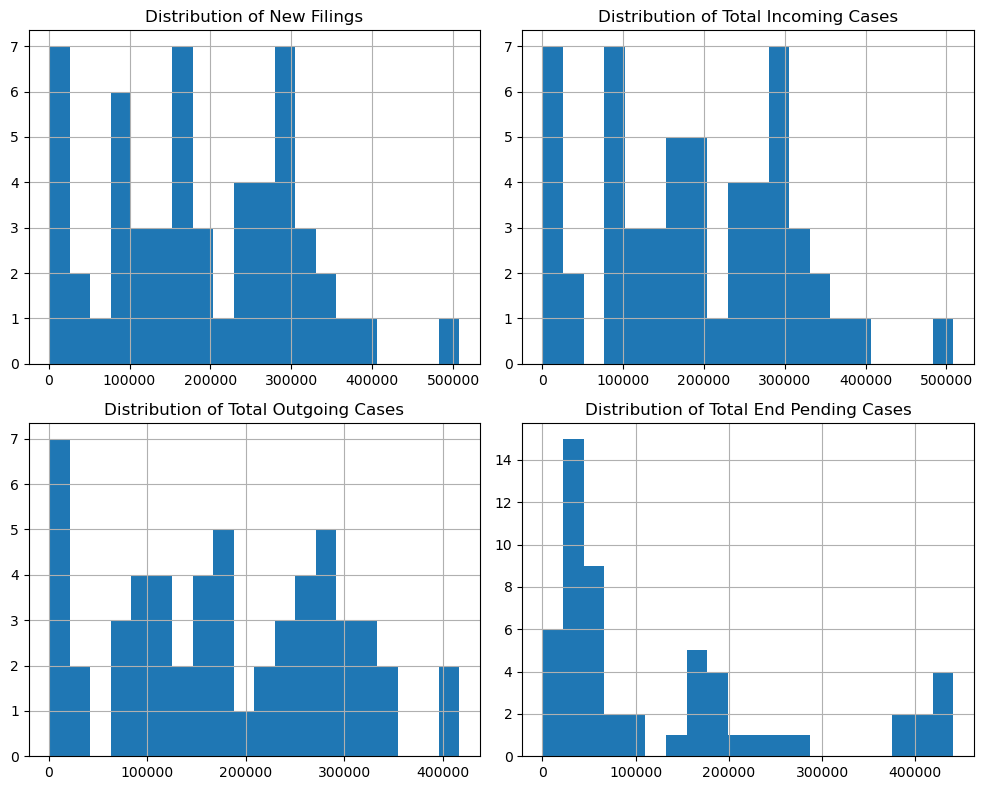

In [40]:
cols = [
    'newfiling',
    'totalincoming',
    'totaloutgoing',
    'totalendpending'
]

axes = df_secondary[cols].hist(
    bins=20,
    figsize=(10, 8)
)

titles = [
    'Distribution of New Filings',
    'Distribution of Total Incoming Cases',
    'Distribution of Total Outgoing Cases',
    'Distribution of Total End Pending Cases'
]

for ax, title in zip(axes.flatten(), titles):
    ax.set_title(title)

plt.tight_layout()
plt.show()

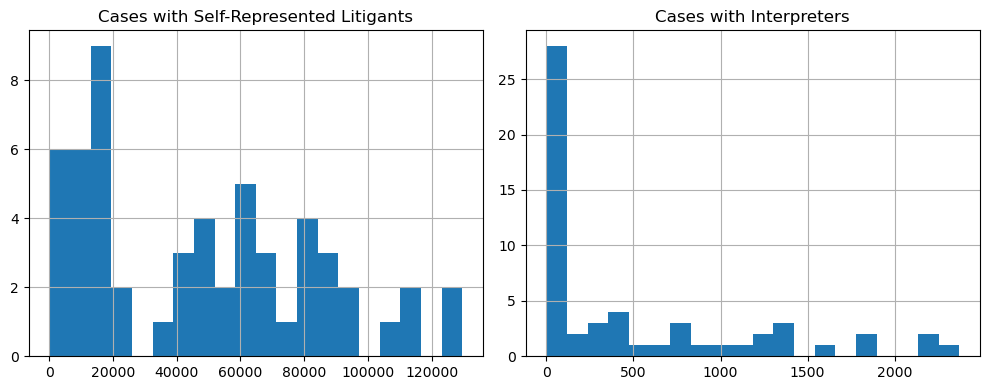

In [41]:
cols = [
    'casewithselfrepresentedlitigants',
    'casewithinterpreters'
]

axes = df_secondary[cols].hist(
    bins=20,
    figsize=(10, 4)
)

titles = [
    'Cases with Self-Represented Litigants',
    'Cases with Interpreters'
]

for ax, title in zip(axes.flatten(), titles):
    ax.set_title(title)

plt.tight_layout()
plt.show()

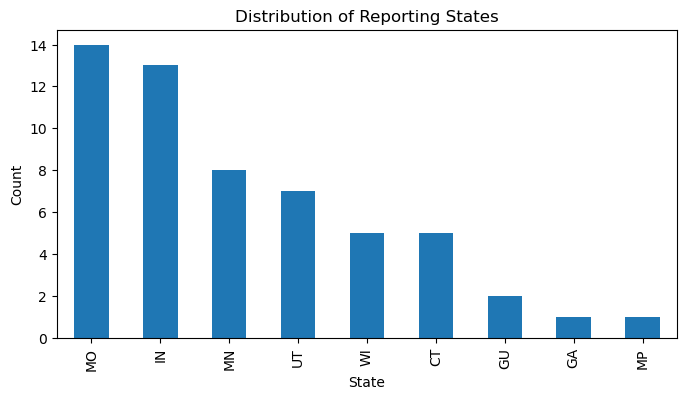

In [42]:
plt.figure(figsize=(8, 4))

(
    df_secondary['reportingstate']
    .value_counts()
    .plot(kind='bar')
)

plt.title('Distribution of Reporting States')
plt.xlabel('State')
plt.ylabel('Count')
plt.show()

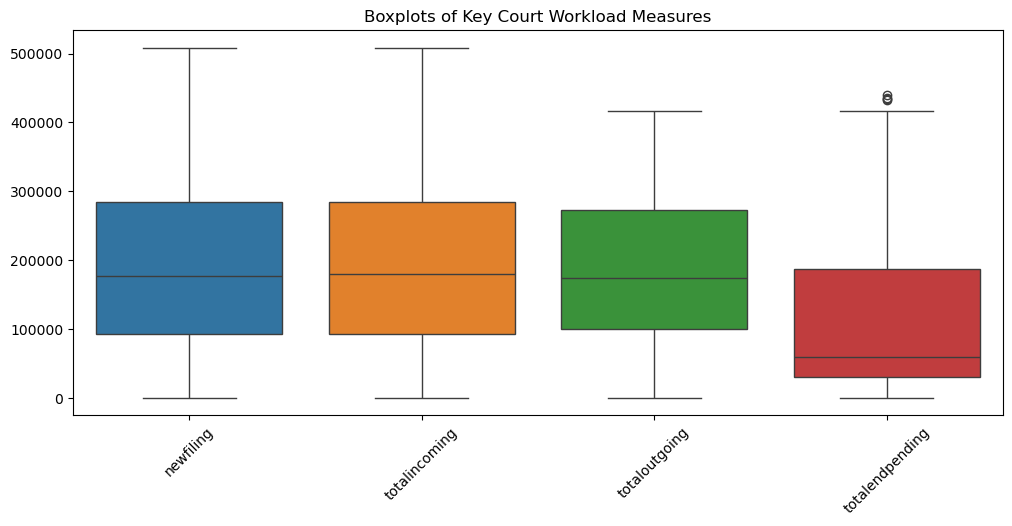

In [43]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df_secondary[
        [
            'newfiling',
            'totalincoming',
            'totaloutgoing',
            'totalendpending'
        ]
    ]
)

plt.title('Boxplots of Key Court Workload Measures')
plt.xticks(rotation=45)
plt.show()

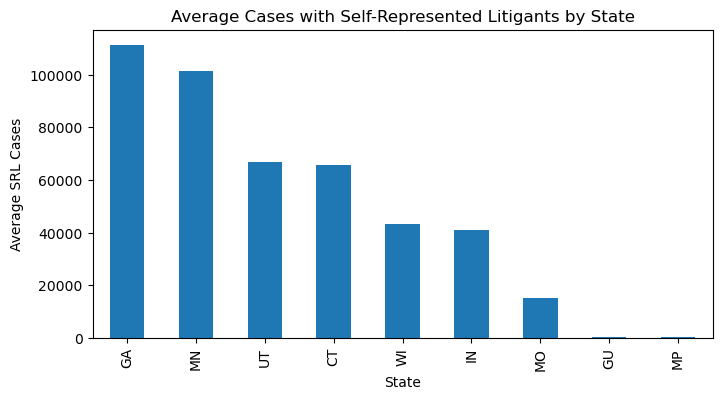

In [44]:
(
    df_secondary.groupby('reportingstate')
    ['casewithselfrepresentedlitigants']
    .mean()
    .sort_values(ascending=False)
    .plot(
        kind='bar',
        figsize=(8,4),
        title='Average Cases with Self-Represented Litigants by State'
    )
)

plt.ylabel('Average SRL Cases')
plt.xlabel('State')
plt.show()

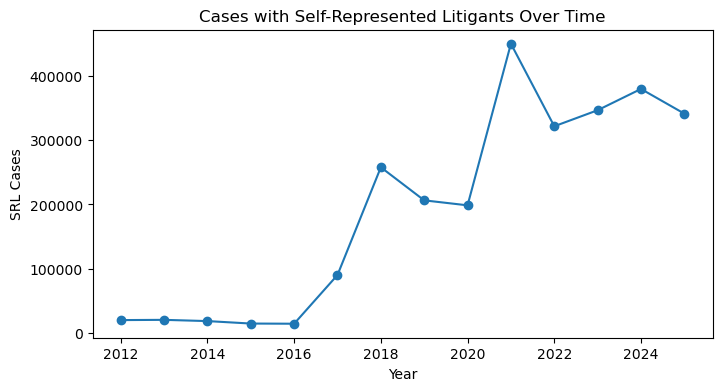

In [45]:
(
    df_secondary.groupby('reportingdate')
    ['casewithselfrepresentedlitigants']
    .sum()
    .plot(
        marker='o',
        figsize=(8,4),
        title='Cases with Self-Represented Litigants Over Time'
    )
)

plt.ylabel('SRL Cases')
plt.xlabel('Year')
plt.show()

The exploratory analysis identified variation in court activity and access-to-justice indicators across jurisdictions. Cases involving self-represented litigants were particularly informative because they may reflect barriers to legal representation and court access. Together with filings, dispositions, interpreter use, and pending caseloads, these variables provide meaningful information that can support future predictive modeling.

---

## Model Selection, Model Training and Evaluation

Create primary modeling dataset.

In [46]:
model_df = df_primary[
    [
        'geoid',
        'year',
        'statename20',
        'population',
        'popdensity',
        'primaryruca'
    ]
].copy()

In [47]:
all_barrier_cols = (
    household_cols +
    education_cols +
    disability_cols +
    mobility_cols +
    language_cols +
    digital_cols +
    transportation_cols
)

Since missingness is relatively low for most barrier categories, perform median imputation for missing values in the barrier columns.

In [48]:
df_barriers = df_primary[all_barrier_cols].copy()
df_barriers = df_barriers.fillna(
    df_barriers.median()
)

Variables were standardized using z-scores to place all measures on a common scale. This ensured that variables with larger values did not disproportionately influence barrier scores and allowed meaningful comparisons across barrier categories.

In [49]:
from sklearn.preprocessing import StandardScaler

In [50]:
scaler = StandardScaler()

z_df = pd.DataFrame(
    scaler.fit_transform(df_barriers),
    columns=[f'z_{c}' for c in all_barrier_cols],
    index=df_primary.index
)

In [51]:
model_df = pd.concat(
    [model_df, z_df],
    axis=1
)

In [52]:
model_df.filter(regex='^z_').head()

,z_households_by_type_total_households_married_couple_family,z_households_by_type_total_households_cohabiting_couple_household,z_households_by_type_total_households_male_householder_no_spouse/partner_present,z_households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone,z_households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,z_households_by_type_total_households_female_householder_no_spouse/partner_present,z_households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone,z_households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,z_households_by_type_total_households_households_with_one_or_more_people_under_18_years,z_households_by_type_total_households_households_with_one_or_more_people_65_years_and_over,...,"z_language_spoken_at_home_population_5_years_and_over_other_indo_european_languages_speak_english_less_than_very_well""""",z_language_spoken_at_home_population_5_years_and_over_asian_and_pacific_islander_languages,"z_language_spoken_at_home_population_5_years_and_over_asian_and_pacific_islander_languages_speak_english_less_than_very_well""""",z_language_spoken_at_home_population_5_years_and_over_other_languages,"z_language_spoken_at_home_population_5_years_and_over_other_languages_speak_english_less_than_very_well""""",z_computers_and_internet_use_total_households_with_a_computer,z_computers_and_internet_use_total_households_with_a_broadband_internet_subscription,z_transportation_households_no_vehicle,z_transportation_households_one_vehicle,z_transportation_households_high_vehicle_access
0,-0.663788,-1.119735,-0.980408,-0.850529,-0.244305,-1.050017,-1.033389,-0.902824,-0.873300,-0.949351,...,-0.522478,-0.365524,-0.426082,-0.364275,-0.327647,-1.234835,-1.274980,-0.530670,-1.020228,-0.292468
1,-1.223206,-0.795385,-0.733300,-0.700980,-0.778726,-0.882595,-0.788115,-0.506724,-1.050159,-0.922910,...,-0.498888,-0.365524,-0.439671,-0.364275,-0.327647,-1.420952,-1.419536,-0.314042,-0.870576,-1.023588
2,-0.121322,0.754286,-0.382751,-0.273699,-0.549688,-0.339496,-0.459087,-0.120781,0.503939,-0.386542,...,-0.475298,-0.365524,-0.290192,-0.199356,-0.327647,-0.214291,-0.245609,-0.383179,-0.148921,0.647544
3,0.629412,-0.747333,-0.032203,-0.352034,-0.301565,-0.180241,0.240843,0.183911,-0.481953,0.678639,...,-0.534272,-0.365524,-0.381917,-0.364275,0.765582,0.227738,0.164234,-0.244906,0.339943,-0.057465
4,0.813463,-1.227852,-0.336778,-0.394762,-0.301565,0.175020,0.372454,-0.313753,0.398577,-0.197681,...,0.185211,0.113445,-0.167890,0.143169,-0.327647,0.336306,0.389806,-0.373961,-0.009246,0.160130


In [53]:
# Transportation
transportation_z = [
    f'z_{c}'
    for c in transportation_cols
]

model_df['transportation_score'] = (
    model_df[transportation_z]
    .mean(axis=1)
)

# Digital
digital_z = [
    f'z_{c}'
    for c in digital_cols
]

model_df['digital_score'] = (
    model_df[digital_z]
    .mean(axis=1)
)

# Education
education_z = [
    f'z_{c}'
    for c in education_cols
]

model_df['education_score'] = (
    model_df[education_z]
    .mean(axis=1)
)

# Language
language_z = [
    f'z_{c}'
    for c in language_cols
]

model_df['language_score'] = (
    model_df[language_z]
    .mean(axis=1)
)

# Disability
disability_z = [
    f'z_{c}'
    for c in disability_cols
]

model_df['disability_score'] = (
    model_df[disability_z]
    .mean(axis=1)
)

# Household
household_z = [
    f'z_{c}'
    for c in household_cols
]

model_df['household_score'] = (
    model_df[household_z]
    .mean(axis=1)
)

# Mobility
mobility_z = [
    f'z_{c}'
    for c in mobility_cols
]

model_df['mobility_score'] = (
    model_df[mobility_z]
    .mean(axis=1)
)

In [54]:
model_df = model_df[
    [
        'geoid',
        'year',
        'statename20',
        'population',
        'popdensity',
        'primaryruca',
        'transportation_score',
        'digital_score',
        'education_score',
        'language_score',
        'disability_score',
        'household_score',
        'mobility_score'
    ]
]

In [55]:
model_df.describe()

,year,population,popdensity,primaryruca,transportation_score,digital_score,education_score,language_score,disability_score,household_score,mobility_score
count,426949.000000,424297.000000,424297.000000,424297.000000,4.269490e+05,4.269490e+05,4.269490e+05,4.269490e+05,4.269490e+05,4.269490e+05,4.269490e+05
mean,2021.999906,3918.718912,5410.815435,2.727757,1.278131e-17,2.556262e-17,2.769284e-17,-5.325547e-18,1.704175e-17,-1.065109e-17,2.130219e-18
std,1.414204,1716.226498,12285.131509,6.803715,5.702480e-01,9.977170e-01,6.554244e-01,5.621821e-01,7.194918e-01,5.425674e-01,7.632598e-01
min,2020.000000,0.000000,0.000000,1.000000,-1.206178e+00,-2.264911e+00,-1.478352e+00,-7.757753e-01,-1.574634e+00,-1.815501e+00,-1.251448e+00
25%,2021.000000,2725.000000,313.500000,1.000000,-3.755955e-01,-6.821018e-01,-4.486834e-01,-3.745787e-01,-4.959663e-01,-3.584372e-01,-4.782271e-01
50%,2022.000000,3756.000000,2206.800000,1.000000,-6.165534e-02,-9.326840e-02,-6.691845e-02,-1.585923e-01,-8.405259e-02,-5.231380e-02,-1.441206e-01
75%,2023.000000,4925.000000,5379.600000,2.000000,3.014591e-01,5.826285e-01,3.846656e-01,2.152817e-01,4.138874e-01,3.074624e-01,3.041297e-01
max,2024.000000,37892.000000,287370.200000,99.000000,1.005378e+01,1.767472e+01,1.306035e+01,1.435163e+01,1.143023e+01,1.000522e+01,2.527417e+01


In [56]:
barrier_scores = [
    'transportation_score',
    'digital_score',
    'education_score',
    'language_score',
    'disability_score',
    'household_score',
    'mobility_score'
]

print(model_df[barrier_scores].corr())

                      transportation_score  digital_score  education_score  \
transportation_score              1.000000       0.873610         0.778442   
digital_score                     0.873610       1.000000         0.917640   
education_score                   0.778442       0.917640         1.000000   
language_score                    0.524254       0.544959         0.668060   
disability_score                  0.712953       0.783656         0.812708   
household_score                   0.874170       0.900239         0.830145   
mobility_score                    0.563961       0.659252         0.624235   

                      language_score  disability_score  household_score  \
transportation_score        0.524254          0.712953         0.874170   
digital_score               0.544959          0.783656         0.900239   
education_score             0.668060          0.812708         0.830145   
language_score              1.000000          0.499158         0.537596   


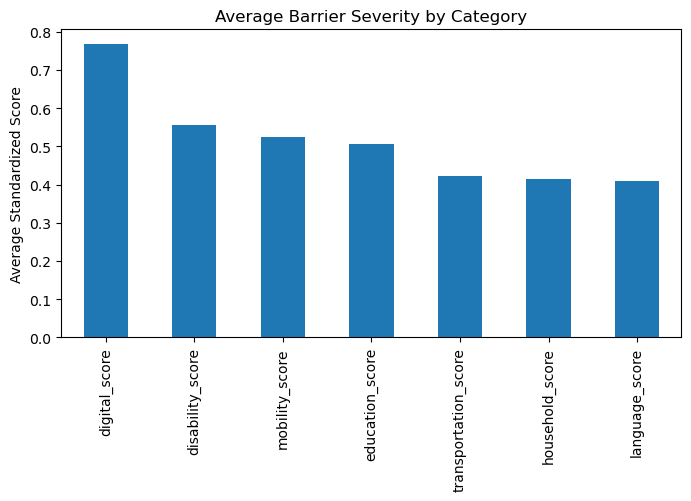

In [57]:
barrier_scores = [
    'transportation_score',
    'digital_score',
    'education_score',
    'language_score',
    'disability_score',
    'household_score',
    'mobility_score'
]

(
    model_df[barrier_scores]
    .abs()
    .mean()
    .sort_values(ascending=False)
    .plot(
        kind='bar',
        figsize=(8,4),
        title='Average Barrier Severity by Category'
    )
)

plt.ylabel('Average Standardized Score')
plt.show()

Digital barriers showed the highest average severity across census tracts, followed by disability, mobility, and education barriers. Transportation barriers ranked in the middle of the barrier categories, suggesting they are an important access challenge but not the most severe barrier overall. However, transportation barriers were strongly correlated with several other barriers, indicating they often occur alongside broader access challenges.

---

#### Model 1: Barrier Relationship Model

To better understand the role of transportation barriers, an initial regression model will be developed using the barrier category scores created during preprocessing. An overall barrier score will serve as the target variable, while transportation, digital, education, language, disability, household, and mobility barriers will be used as predictors. This approach allows the analysis to estimate the relative contribution of transportation barriers and determine how much variance they explain compared to other access barriers.

In [58]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [59]:
y = model_df['transportation_score']

X = model_df[
    [
        'digital_score',
        'education_score',
        'language_score',
        'disability_score',
        'household_score',
        'mobility_score'
    ]
]

In [60]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [61]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Generate predictions.

In [62]:
y_pred = model.predict(X_test)

In [63]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("R²:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R²: 0.813840174361735
MAE: 0.16378004244291056
RMSE: 0.2462627198334012


In [64]:
coef_df = pd.DataFrame({
    'Barrier': X.columns,
    'Coefficient': model.coef_
})

coef_df['Absolute_Impact'] = abs(coef_df['Coefficient'])

coef_df.sort_values(
    'Absolute_Impact',
    ascending=False
)

,Barrier,Coefficient,Absolute_Impact
4,household_score,0.456879,0.456879
0,digital_score,0.387284,0.387284
1,education_score,-0.239588,0.239588
2,language_score,0.107250,0.107250
5,mobility_score,-0.011736,0.011736
3,disability_score,0.009616,0.009616


---

#### Model 2: Transportation Classification

This model classifies census tracts into transportation risk groups based on transportation barrier scores. The objective is to identify communities with the highest transportation barriers and examine how transportation risk relates to other barrier categories. This analysis helps reveal patterns of access challenges and identify areas that may face multiple barriers simultaneously.

In [65]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [66]:
model_df['transportation_risk'] = pd.qcut(
    model_df['transportation_score'],
    q=5,
    labels=[
        'Very Low',
        'Low',
        'Moderate',
        'High',
        'Very High'
    ]
)

In [67]:
model_df['transportation_risk'].value_counts()

transportation_risk
Very Low     85390
Low          85390
High         85390
Very High    85390
Moderate     85389
Name: count, dtype: int64

In [68]:
X = model_df[
    [
        'digital_score',
        'education_score',
        'language_score',
        'disability_score',
        'household_score',
        'mobility_score'
    ]
]

y = model_df['transportation_risk']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [69]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Generate predictions.

In [70]:
y_pred = rf.predict(X_test)

In [71]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.6489518679002225
              precision    recall  f1-score   support

        High       0.55      0.56      0.55     17078
         Low       0.58      0.60      0.59     17078
    Moderate       0.52      0.51      0.52     17078
   Very High       0.79      0.76      0.78     17078
    Very Low       0.80      0.81      0.81     17078

    accuracy                           0.65     85390
   macro avg       0.65      0.65      0.65     85390
weighted avg       0.65      0.65      0.65     85390



In [72]:
importance_df = pd.DataFrame({
    'Barrier': X.columns,
    'Importance': rf.feature_importances_
})

importance_df = importance_df.sort_values(
    'Importance',
    ascending=False
)

print(importance_df)

            Barrier  Importance
0     digital_score    0.272790
4   household_score    0.238281
1   education_score    0.148185
3  disability_score    0.129755
5    mobility_score    0.109334
2    language_score    0.101656


---

---

## Results Interpretation and Recommendations

### Model 1: Transportation Relationship Model (Linear Regression)

The first model used multiple linear regression to examine how transportation barriers relate to other access barriers barriers captured from the ACS survey. Prior EDA included standardizing variables, creating barrier category scores, evaluating distributions, and generating correlation matrices. The correlation analysis showed strong relationships between transportation, digital, household, and education barriers, supporting their inclusion as predictors. Transportation score (standardized) was used as the target variable, while digital, education, language, disability, household, and mobility scores were used as predictors. The model explained approximately 81.4% of the variation in transportation barriers (R² = 0.814), suggesting that transportation barriers are strongly connected to other access-related challenges.

A key strength of this model is the large tract-level dataset, which provided stable and reliable estimates. The results indicated that household, digital, and education barriers were most strongly associated with transportation barriers, suggesting that transportation challenges often occur alongside broader forms of disadvantage. However, the high correlations among some barrier categories indicate overlap between predictors, making it difficult to fully isolate individual effects. Based on these findings, future work should incorporate additional geographic and socioeconomic measures and explore more detailed access-to-justice outcomes to better understand how transportation barriers influence community-level access.

### Model 2: Transportation Risk Classification (Random Forest)

The second model used a Random Forest classification algorithm to classify census tracts into five transportation risk categories ranging from "Very Low" to "Very High." EDA showed meaningful variation in transportation barrier scores across census tracts and revealed strong relationships between transportation barriers and several other barrier categories. These findings supported the use of digital, education, language, disability, household, and mobility scores as predictors of transportation risk. The Random Forest model achieved an overall accuracy of 64.9%, differing from the 20% accuracy expected from random classification across five equally sized categories.

A major strength of this approach is its ability to identify the factors most useful for distinguishing between transportation risk levels while capturing complex relationships that may not be fully explained by linear models. Feature importance results showed that digital barriers (27.3%), household barriers (23.8%), and education barriers (14.8%) were the strongest predictors of transportation risk. These findings reinforce the regression results and suggest that transportation barriers are closely linked with broader patterns of structural disadvantage. Future research should incorporate more detailed transportation accessibility measures, county- or tract-level justice outcomes, and additional geographic variables to better understand how transportation barriers affect access to services and opportunities.

### Recommendations

The model findings helped shape how the secondary dataset should be analyzed and interpreted. Specifically, the results highlighted the importance of considering multiple access barriers simultaneously, as transportation challenges are closely linked with digital, household, and education barriers. While the civil filing dataset was not suitable for reliable predictive modeling due to the limited number of overlapping state-year observations (aggregated at the state-year level), it provides valuable descriptive context for understanding civil justice activity. Across 56 state-year records, courts experienced an average of 185,264 new filings annually, with filing volumes ranging from 546 to 507,803 cases. The dataset also showed substantial variation in self-represented litigant cases, averaging 47,859 annually and reaching as many as 129,655 cases in a single reporting period. These measures can be incorporated into maps and interactive dashboards alongside transportation risk and barrier scores, enabling stakeholders to explore geographic patterns, compare court activity across states and years, and support data-driven decision-making. 